<div dir="rtl">

# אבחון התכנסות — על מודל פשוט: אומדן ממוצע


## במחברת 11 ראינו אבחון התכנסות על מודל היררכי של גדילת חולדות. כאן נחזור על אותם כלים בדיוק, אבל על המודל הפשוט ביותר שיש: **אומדן הממוצע (וסטיית התקן) של מדגם**.


## למה מודל פשוט? כי כאן אנחנו *יודעים בערך מה התשובה* — ממוצע המדגם. כך קל לראות מתי הדוגם עובד, ומתי הוא מחזיר תוצאות שגויות לחלוטין, ולבדוק אילו כלי אבחון מזהים את הבעיה.


## **מה נלמד:**

### 1. שיטות לא פורמליות — גרף עקבות (trace plot), כמה שרשראות מנקודות התחלה שונות, תקופת חימום (burn-in)
### 2. סטטיסטי גלמן-רובין $\hat{R}$ — חישוב ידני והשוואה ל-ArviZ
### 3. גרף דרגות (rank plot)
### 4. אוטוקורלציה
### 5. גודל מדגם אפקטיבי (ESS) ושגיאת מונטה-קרלו (MCSE)
### 6. למה דילול (thinning) לא עוזר

</div>

<div dir="rtl">

## למה צריך אבחון התכנסות?

MCMC מבטיח שהדגימות מגיעות מההתפלגות הפוסטריורית **רק בגבול** — כשמספר האיטרציות שואף לאינסוף. בפועל אנחנו עוצרים אחרי מספר סופי של דגימות, ולכן צריך לבדוק:

- **האם השרשרת הגיעה להתפלגות היעד?** (ולא נשארה תקועה ליד נקודת ההתחלה)
- **האם היא חקרה את כל ההתפלגות?** — מה שנקרא *ערבוב* (mixing) טוב
- **כמה מידע באמת יש בדגימות?** — דגימות עוקבות תלויות זו בזו, ולכן 1000 דגימות שוות פחות מ-1000 דגימות בלתי תלויות

חשוב לזכור: כל כלי האבחון הם **היוריסטיים**. אם הם מצביעים על בעיה — כנראה שיש בעיה. אבל אם הם לא מצביעים על בעיה — זה **לא מבטיח** התכנסות. וגם מודל שהתכנס אינו בהכרח מודל טוב; זו שאלה נפרדת של *התאמת המודל* (goodness of fit).

</div>

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
import pymc as pm
import warnings
warnings.simplefilter('ignore')

az.style.use('arviz-white')
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

<div dir="rtl">

## הנתונים: גובה של 30 סטודנטים

נייצר נתונים מדומים: 30 מדידות גובה (בס"מ) מהתפלגות נורמלית עם ממוצע אמיתי 170 וסטיית תקן 7. במציאות לא היינו יודעים את הערכים האלה — המטרה היא לאמוד אותם מהנתונים.

</div>

n = 30
sample mean = 170.12
sample std  = 5.45


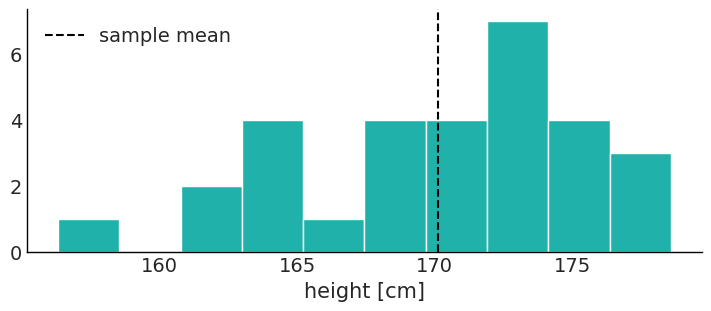

In [2]:
true_mu, true_sigma = 170, 7
heights = rng.normal(true_mu, true_sigma, size=30).round(1)

print(f'n = {len(heights)}')
print(f'sample mean = {heights.mean():.2f}')
print(f'sample std  = {heights.std(ddof=1):.2f}')

plt.figure(figsize=(7, 3))
plt.hist(heights, bins=10, color='LightSeaGreen', edgecolor='white')
plt.axvline(heights.mean(), color='k', ls='--', label='sample mean')
plt.xlabel('height [cm]')
plt.legend();

<div dir="rtl">

## המודל

מודל נורמלי עם ממוצע וסטיית תקן לא ידועים:

$$\mu \sim \text{Normal}(160, 20)$$

$$\sigma \sim \text{HalfNormal}(15)$$

$$y_i \sim \text{Normal}(\mu, \sigma)$$

ה-priors רחבים ביחס לנתונים, ולכן הפוסטריור של $\mu$ צריך להיות קרוב מאוד לממוצע המדגם, עם סטיית תקן של בערך $s/\sqrt{n}$.

</div>

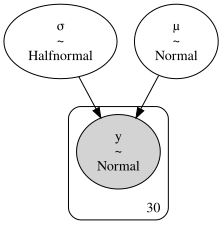

In [3]:
with pm.Model() as mean_model:
    μ = pm.Normal('μ', mu=160, sigma=20)
    σ = pm.HalfNormal('σ', sigma=15)
    y = pm.Normal('y', mu=μ, sigma=σ, observed=heights)

try:
    display(pm.model_to_graphviz(mean_model))
except ImportError:
    print('graphviz is not installed - skipping the model graph')

<div dir="rtl">

## דגימה "טובה": NUTS עם 4 שרשראות

נריץ את הדוגם ברירת המחדל של PyMC — NUTS — עם 4 שרשראות, 1000 צעדי כיוונון (tune) ו-1000 דגימות בכל שרשרת. צעדי הכיוונון הם בדיוק תקופת החימום: PyMC משתמש בהם כדי להתאים את גודל הצעד, ואז זורק אותם.

</div>

In [4]:
with mean_model:
    idata_good = pm.sample(1000, tune=1000, chains=4, cores=1, random_seed=1)

Output()

<div dir="rtl">

## 1. שיטות לא פורמליות

### גרף עקבות (trace plot)

הכלי הפשוט ביותר: מציירים את ערכי הדגימות לאורך האיטרציות. בצד שמאל — ההתפלגות של כל שרשרת, ובצד ימין — הערכים לפי סדר הדגימה.

**איך נראית התכנסות טובה?**

- הצפיפויות של כל השרשראות כמעט חופפות
- העקבות נראות כמו "רעש לבן" — *זחל שעיר* (fuzzy caterpillar): קופצות מהר סביב ערך קבוע, בלי מגמה ובלי קטעים "תקועים"
- כל השרשראות מעורבבות זו בזו, ואי אפשר להבחין ביניהן

</div>

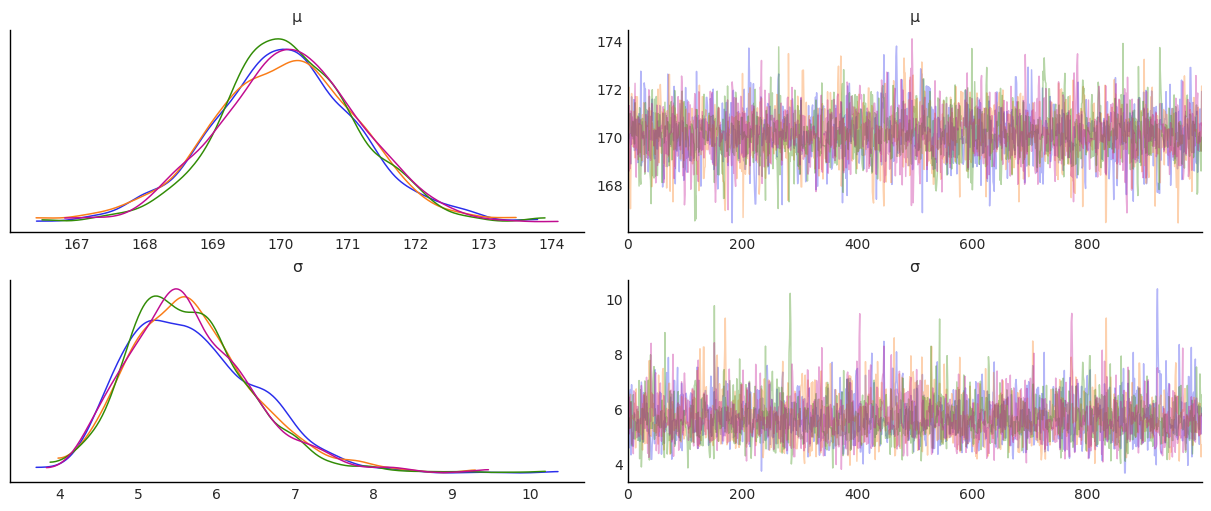

In [ ]:
az.plot_trace(idata_good, compact=False, figsize=(12, 5));

<div dir="rtl">

### דגימה "רעה": מטרופוליס, בלי חימום, מנקודות התחלה רחוקות

עכשיו נקלקל את הדגימה בכוונה, בשלוש דרכים:

1. **דוגם מטרופוליס** במקום NUTS — הצעות של הליכה מקרית, שזזות לאט
2. **בלי צעדי כיוונון** (`tune=0`) — אין התאמה של גודל הצעד, ואף דגימה לא נזרקת
3. **נקודות התחלה רחוקות ושונות** לכל שרשרת: $\mu = 110, 140, 200, 230$

זה בדיוק התרגיל שעשינו במחברת 11 עם `start={'m_a': 1000}` — רק שכאן אנחנו יודעים שהתשובה הנכונה היא בסביבת 170.

</div>

In [12]:
starts = [{'μ': 70., 'σ': 5.}, {'μ': 240., 'σ': 5.},
          {'μ': 200., 'σ': 5.}, {'μ': 230., 'σ': 5.}]

with mean_model:
    idata_bad = pm.sample(1000, tune=0, chains=4, cores=1,
                          step=pm.Metropolis(), initvals=starts,
                          random_seed=2)

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


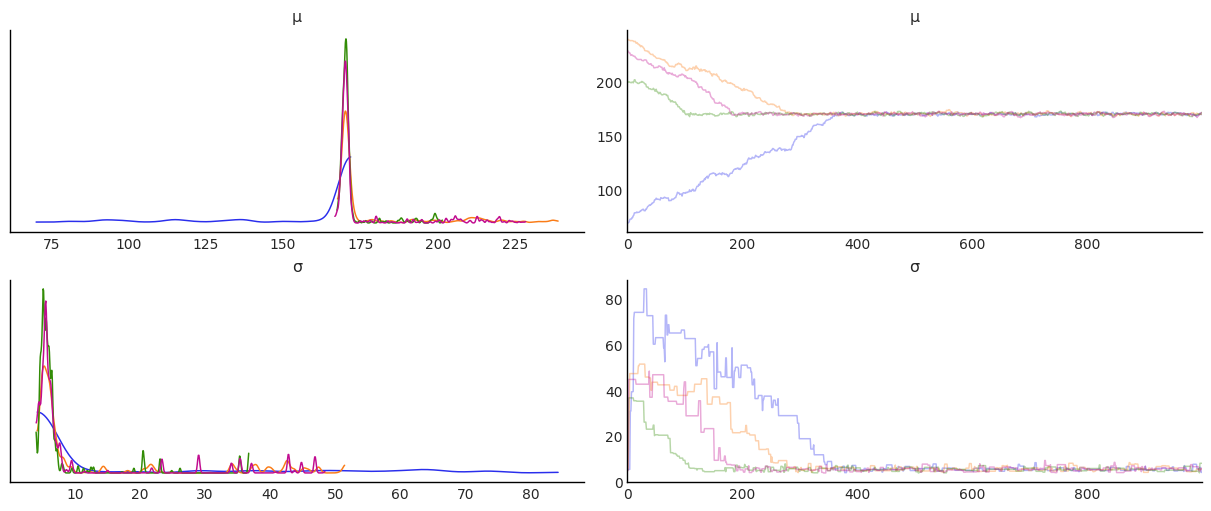

In [13]:
az.plot_trace(idata_bad, compact=False, figsize=(12, 5));

<div dir="rtl">

כבר בעין רואים שמשהו לא בסדר: כל שרשרת מתחילה במקום אחר, והצפיפויות בצד שמאל לא חופפות בכלל. נצייר את $\mu$ של כל השרשראות על אותם צירים, יחד עם ממוצע המדגם:

</div>

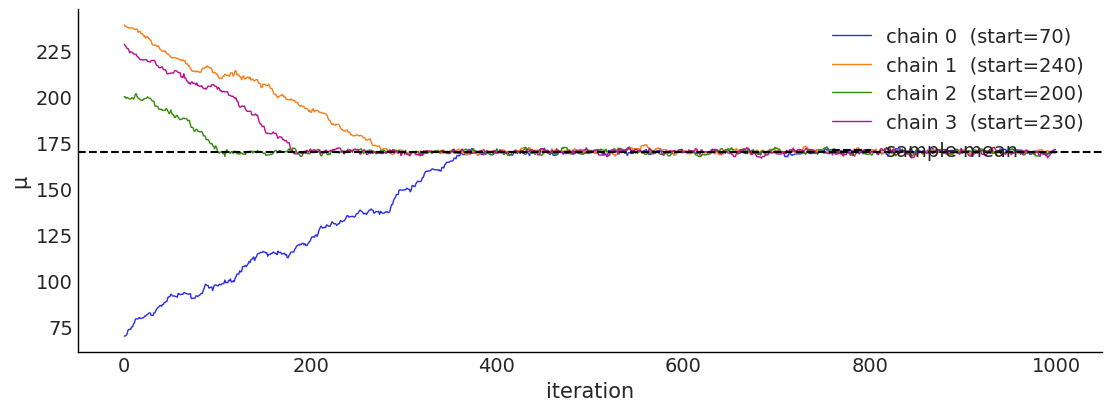

In [14]:
mu_bad = idata_bad.posterior['μ'].values        # shape: (chains, draws)

plt.figure(figsize=(11, 4))
for c in range(mu_bad.shape[0]):
    plt.plot(mu_bad[c], lw=1, label=f'chain {c}  (start={starts[c]["μ"]:.0f})')
plt.axhline(heights.mean(), color='k', ls='--', label='sample mean')
plt.xlabel('iteration'); plt.ylabel('μ')
plt.legend(loc='upper right');

<div dir="rtl">

### תקופת חימום (burn-in)

כל השרשראות מתקרבות בסוף לאותו אזור — סביב 170. זו **ארגודיות**: שרשרת מרקוב תקינה מגיעה להתפלגות היעד מכל נקודת התחלה. אבל הדגימות הראשונות, שבהן השרשרת עוד "בדרך", אינן דגימות מהפוסטריור. אם נשאיר אותן, הן יעוותו את הממוצע ויגדילו מאוד את סטיית התקן.

הפתרון: לזרוק את תחילת השרשרת. מהגרף נראה שאחרי כ-250 איטרציות כל השרשראות כבר באזור הנכון. כדי להיות בטוחים נשאיר מרווח ביטחון, ונזרוק את 500 האיטרציות הראשונות:

</div>

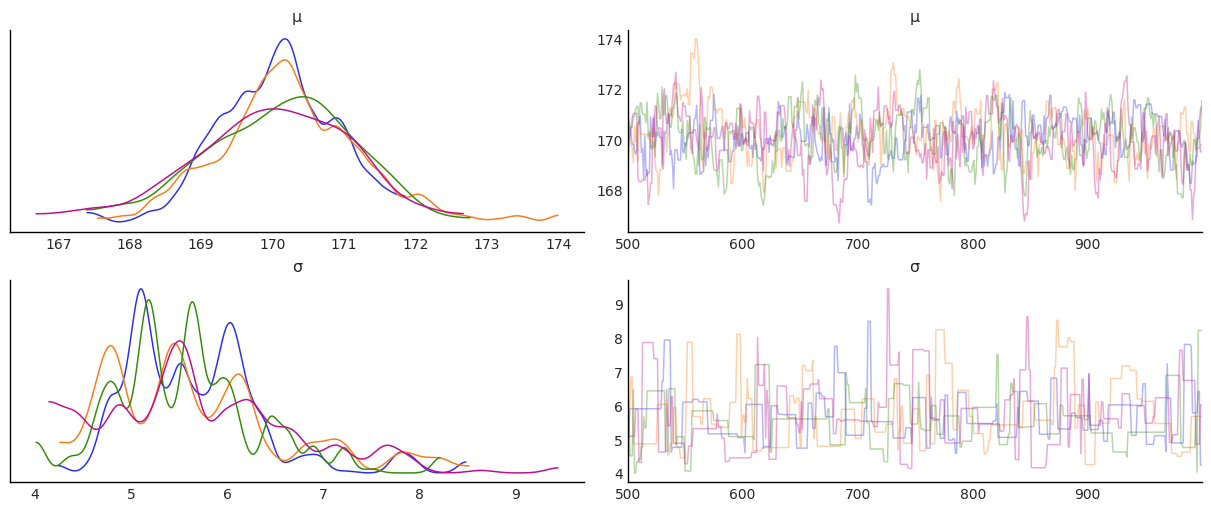

In [15]:
burn = 500
idata_burned = idata_bad.sel(draw=slice(burn, None))

az.plot_trace(idata_burned, compact=False, figsize=(12, 5));

<div dir="rtl">

זה נראה הרבה יותר טוב. אבל שימו לב: את נקודת החיתוך בחרנו **בעין**. אנחנו צריכים כלים כמותיים שיגידו לנו אם השרשראות התכנסו.

### אזהרה: יציבות-מדומה (metastability)

הסיבה העיקרית ששיטות לא פורמליות אינן מבטיחות התכנסות היא *יציבות-מדומה*: שרשרת יכולה להיראות יציבה לגמרי לאורך זמן רב, ואז לקפוץ פתאום לאזור אחר במרחב הפרמטרים (למשל בפוסטריור עם כמה "פסגות"). במודל הפשוט שלנו יש פסגה אחת, ולכן הבעיה הזו לא תופיע — אבל במודלים מורכבים היא בהחלט קיימת, ואין כלי סטטיסטי שמזהה אותה בוודאות.

</div>

<div dir="rtl">

## 2. סטטיסטי גלמן-רובין $\hat{R}$

הרעיון: אם כל השרשראות התכנסו לאותה התפלגות, הן צריכות להיראות **דומות זו לזו**. משווים את השונות *בין* השרשראות לשונות *בתוך* כל שרשרת — בדומה לניתוח שונות (ANOVA).

נניח $m$ שרשראות, כל אחת באורך $n$, ו-$\theta_{ij}$ היא הדגימה ה-$i$ בשרשרת ה-$j$:

**השונות בין השרשראות** — כמה ממוצעי השרשראות רחוקים מהממוצע הכללי:

$$B = \frac{n}{m-1} \sum_{j=1}^m (\bar{\theta}_{.j} - \bar{\theta}_{..})^2$$

**השונות בתוך השרשראות** — ממוצע השונויות של כל שרשרת:

$$W = \frac{1}{m} \sum_{j=1}^m \left[ \frac{1}{n-1} \sum_{i=1}^n (\theta_{ij} - \bar{\theta}_{.j})^2 \right]$$

**אומדן השונות הפוסטריורית** — שילוב של השניים:

$$\hat{\text{Var}}(\theta | y) = \frac{n-1}{n} W + \frac{1}{n} B$$

**והסטטיסטי:**

$$\hat{R} = \sqrt{\frac{\hat{\text{Var}}(\theta | y)}{W}}$$

כשהשרשראות מתחילות בנקודות מפוזרות, $\hat{\text{Var}}$ *מעריך ביתר* את השונות האמיתית, ו-$W$ *מעריך בחסר* (כל שרשרת עוד לא חקרה את כל ההתפלגות). לכן $\hat{R} > 1$. כשהשרשראות מתכנסות, שני האומדנים מתקרבים לשונות האמיתית ו-$\hat{R} \to 1$.

נממש את הנוסחה בעצמנו:

</div>

In [16]:
def rhat_classic(x):
    # x: array of shape (chains, draws)
    m, n = x.shape
    chain_means = x.mean(axis=1)
    B = n * chain_means.var(ddof=1)            # between-chain variance
    W = x.var(axis=1, ddof=1).mean()           # within-chain variance
    var_hat = (n - 1) / n * W + B / n          # pooled posterior variance
    return np.sqrt(var_hat / W)


mu_good = idata_good.posterior['μ'].values
mu_burned = idata_burned.posterior['μ'].values

print(f'good   : R-hat = {rhat_classic(mu_good):.4f}')
print(f'bad    : R-hat = {rhat_classic(mu_bad):.4f}')
print(f'burned : R-hat = {rhat_classic(mu_burned):.4f}')

good   : R-hat = 0.9995
bad    : R-hat = 1.2023
burned : R-hat = 1.0063


<div dir="rtl">

אותו חישוב ב-ArviZ: השיטה `identity` היא הנוסחה הקלאסית שמימשנו. ברירת המחדל, השיטה `rank`, היא גרסה משופרת (Vehtari et al., 2021): היא מפצלת כל שרשרת לשני חצאים — כך שגם שרשרת אחת שעדיין "זוחלת" תתגלה — ועובדת על דרגות (ranks) במקום על הערכים עצמם, כך שהיא עמידה גם להתפלגויות עם זנבות כבדים.

</div>

In [17]:
rows = {}
for name, idata in [('good', idata_good), ('bad', idata_bad), ('burned', idata_burned)]:
    rows[name] = {
        'manual':     rhat_classic(idata.posterior['μ'].values),
        'identity':   float(az.rhat(idata, var_names=['μ'], method='identity')['μ']),
        'rank (default)': float(az.rhat(idata, var_names=['μ'])['μ']),
    }
pd.DataFrame(rows).T.round(4)

,manual,identity,rank (default)
good,0.9995,0.9995,1.0019
bad,1.2023,1.2023,1.3400
burned,1.0063,1.0063,1.0239


<div dir="rtl">

**כלל אצבע:** בעבר המליצו על $\hat{R} < 1.1$. היום ההמלצה מחמירה יותר: $\hat{R} < 1.01$, ו-PyMC מדפיס אזהרה כשהערך גבוה מזה — בדיוק האזהרה שראינו אחרי הדגימה הרעה.

שימו לב לשורה האחרונה: גם אחרי החיתוך, $\hat{R}$ של הדגימה הרעה עדיין מעל 1.01 (בעיקר בגרסת ה-rank). החיתוך פתר את בעיית נקודת ההתחלה, אבל לא את הבעיה שהשרשראות זזות לאט, ולכן 500 הדגימות שנשארו בכל שרשרת עדיין לא מספיקות כדי שהן "יסכימו" זו עם זו. לזה נגיע בחלק על האוטוקורלציה.

### איך $\hat{R}$ משתנה לאורך הדגימה?

נחשב את $\hat{R}$ על $k$ הדגימות הראשונות, עבור $k$ הולך וגדל. בדגימה הטובה הוא קרוב ל-1 כמעט מההתחלה; בדגימה הרעה הוא יורד לאט, כשהשרשראות מתקרבות זו לזו.

</div>

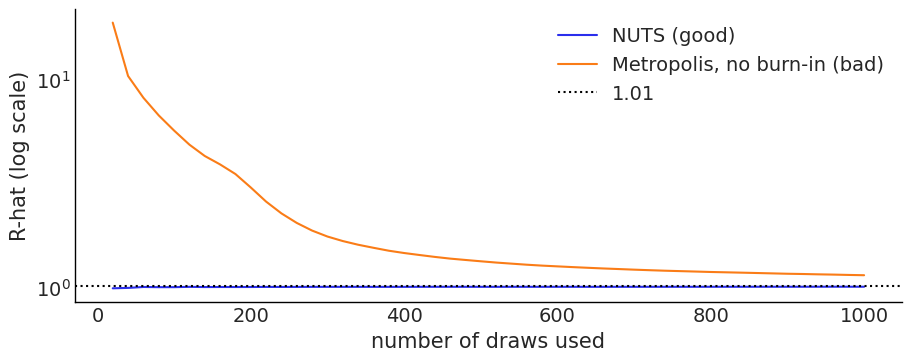

In [ ]:
ks = np.arange(20, 1001, 20)
plt.figure(figsize=(9, 3.5))
plt.plot(ks, [rhat_classic(mu_good[:, :k]) for k in ks], label='NUTS (good)')
plt.plot(ks, [rhat_classic(mu_bad[:, :k]) for k in ks], label='Metropolis, no burn-in (bad)')
plt.axhline(1.01, color='k', ls=':', label='1.01')
plt.yscale('log')
plt.xlabel('number of draws used'); plt.ylabel('R-hat (log scale)')
plt.legend();

<div dir="rtl">

## 3. גרף דרגות (rank plot)

גרף עקבות קשה לקרוא כשיש הרבה שרשראות או הרבה דגימות. חלופה מומלצת היא **גרף דרגות**: מדרגים את כל הדגימות מכל השרשראות יחד, ואז מציירים היסטוגרמה של הדרגות לכל שרשרת בנפרד.

- אם השרשראות מעורבבות היטב, לכל שרשרת יש בערך אותו חלק מהדרגות הנמוכות, הבינוניות והגבוהות — ולכן **ההיסטוגרמות שטוחות** (אחידות)
- אם שרשרת "תקועה" באזור גבוה או נמוך — ההיסטוגרמה שלה מוטה לצד אחד

</div>

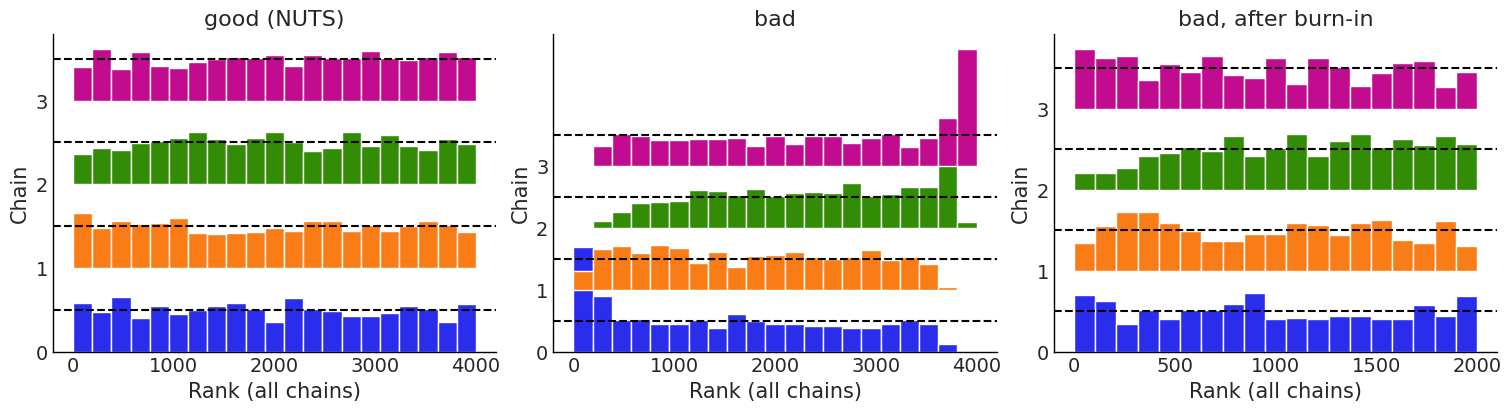

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
az.plot_rank(idata_good, var_names=['μ'], ax=axes[0])
az.plot_rank(idata_bad, var_names=['μ'], ax=axes[1])
az.plot_rank(idata_burned, var_names=['μ'], ax=axes[2])
axes[0].set_title('good (NUTS)'); axes[1].set_title('bad'); axes[2].set_title('bad, after burn-in');

<div dir="rtl">

## 4. אוטוקורלציה

**הגדרה:** האוטוקורלציה בפיגור (lag) $k$ מודדת את המתאם בין ערך בשרשרת לבין הערך שמגיע $k$ צעדים אחריו:

$$\rho(k) = \frac{\mathrm{Cov}(x_t, x_{t+k})}{\sqrt{\mathrm{Var}(x_t)\mathrm{Var}(x_{t+k})}}$$

כל שרשרת MCMC היא אוטוקורלטיבית — כל צעד תלוי בצעד הקודם. זה כשלעצמו לא פסול, אבל ככל שהאוטוקורלציה גבוהה יותר ודועכת לאט יותר, כל דגימה חדשה מוסיפה פחות מידע, וצריך יותר דגימות כדי לתאר את הפוסטריור.

נחשב בעצמנו את האוטוקורלציה של שרשרת אחת:

</div>

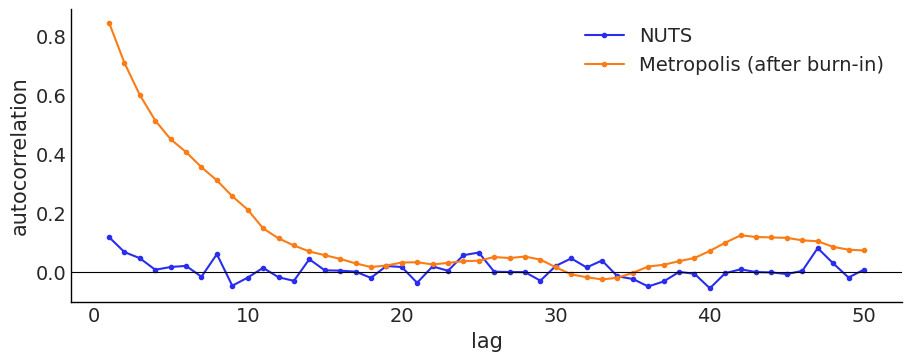

In [ ]:
def autocorr(x, lag):
    # correlation between x[t] and x[t + lag]
    return np.corrcoef(x[:-lag], x[lag:])[0, 1]


lags = np.arange(1, 51)
chain_good = mu_good[0]
chain_bad = mu_burned[0]

plt.figure(figsize=(9, 3.5))
plt.plot(lags, [autocorr(chain_good, k) for k in lags], 'o-', ms=3, label='NUTS')
plt.plot(lags, [autocorr(chain_bad, k) for k in lags], 'o-', ms=3, label='Metropolis (after burn-in)')
plt.axhline(0, color='k', lw=0.8)
plt.xlabel('lag'); plt.ylabel('autocorrelation')
plt.legend();

<div dir="rtl">

אצל NUTS האוטוקורלציה נעלמת כמעט מיד: כל דגימה כמעט בלתי תלויה בקודמת. אצל מטרופוליס היא דועכת לאט — צריך עשרות צעדים עד שהשרשרת "שוכחת" איפה הייתה.

אותו דבר עם הפונקציה המובנית של ArviZ (לכל השרשראות):

</div>

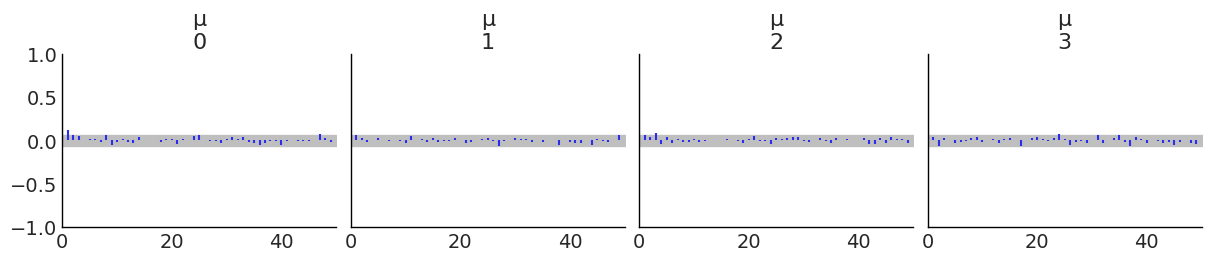

In [ ]:
az.plot_autocorr(idata_good, var_names=['μ'], max_lag=50, figsize=(12, 2.5));

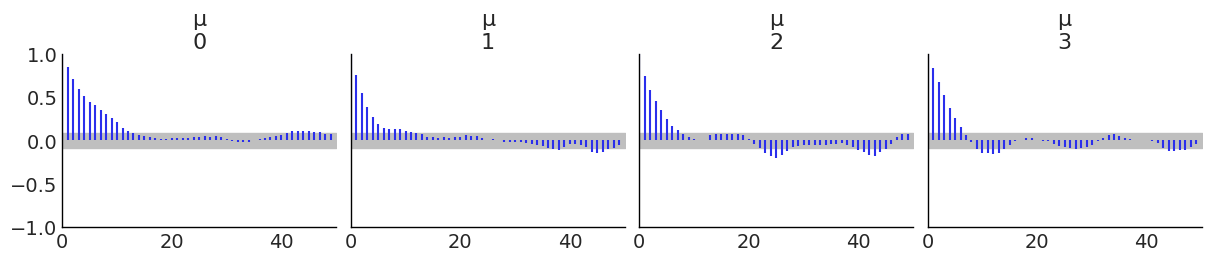

In [ ]:
az.plot_autocorr(idata_burned, var_names=['μ'], max_lag=50, figsize=(12, 2.5));

<div dir="rtl">

## 5. גודל מדגם אפקטיבי (ESS)

הבעיה העיקרית של אוטוקורלציה גבוהה היא ש**גודל המדגם האפקטיבי** קטן מאוד. ESS עונה על השאלה: *לכמה דגימות בלתי תלויות שוות הדגימות שלנו?*

$$\hat{n}_{\text{eff}} = \frac{mn}{1 + 2\sum_{t=1}^T \hat{\rho}_t}$$

כאן $mn$ הוא המספר הכולל של הדגימות, ו-$\hat{\rho}_t$ היא האוטוקורלציה בפיגור $t$. סוכמים עד הפיגור האי-זוגי הראשון $T$ שבו $\hat{\rho}_{T+1} + \hat{\rho}_{T+2}$ שלילי — כי מעבר לשם האוטוקורלציות הן כבר בעיקר רעש.

את האוטוקורלציה מחשבים יחד לכל השרשראות, בעזרת ה*וריוגרמה* (variogram) — הממוצע של ריבועי ההפרשים בין דגימות במרחק $t$:

$$V_t = \frac{1}{m(n-t)}\sum_{j=1}^m \sum_{k=t+1}^n (\theta_{jk} - \theta_{j(k-t)})^2, \qquad \hat{\rho}_t = 1 - \frac{V_t}{2\,\hat{\text{Var}}(\theta | y)}$$

כאשר $\hat{\text{Var}}$ הוא אותו אומדן שונות מסטטיסטי גלמן-רובין.

**אינטואיציה:** אם $\rho$ גבוה, הסכום במכנה גדול, ו-ESS קטן בהרבה ממספר הדגימות. אם הדגימות בלתי תלויות, כל ה-$\rho$ הן אפס ו-ESS שווה למספר הדגימות.

</div>

In [ ]:
def ess_manual(x):
    # x: array of shape (chains, draws)
    m, n = x.shape
    W = x.var(axis=1, ddof=1).mean()
    B = n * x.mean(axis=1).var(ddof=1)
    var_hat = (n - 1) / n * W + B / n

    def rho(t):
        V = np.mean((x[:, t:] - x[:, :-t]) ** 2)    # variogram at lag t
        return 1 - V / (2 * var_hat)

    total, T = 0.0, 1
    while T + 2 < n:
        total += rho(T)
        if rho(T + 1) + rho(T + 2) < 0:              # stop at the first odd T
            break
        total += rho(T + 1)                          # continue to next odd T
        T += 2
    return m * n / (1 + 2 * total)


for name, x in [('good', mu_good), ('burned', mu_burned)]:
    print(f'{name:7s}: draws = {x.size:5d}   ESS (manual) = {ess_manual(x):7.1f}')

good   : draws =  4000   ESS (manual) =  3144.7
burned : draws =  2000   ESS (manual) =   220.3


<div dir="rtl">

ArviZ מחשב שני סוגים של ESS:

- **`ess_bulk`** — כמה מידע יש לנו על *מרכז* ההתפלגות (ממוצע, חציון)
- **`ess_tail`** — כמה מידע יש לנו על *הזנבות* (למשל על גבולות ה-HDI ב-3% ו-97%)

כלל אצבע: לפחות 100 דגימות אפקטיביות **לכל שרשרת** (כלומר 400 עבור 4 שרשראות) גם ב-bulk וגם ב-tail.

</div>

In [ ]:
rows = {}
for name, idata in [('good', idata_good), ('bad', idata_bad), ('burned', idata_burned)]:
    n_draws = idata.posterior.sizes['chain'] * idata.posterior.sizes['draw']
    bulk = float(az.ess(idata, var_names=['μ'])['μ'])
    tail = float(az.ess(idata, var_names=['μ'], method='tail')['μ'])
    rows[name] = {'draws': n_draws, 'ess_bulk': bulk, 'ess_tail': tail,
                  'ess_bulk / draws': bulk / n_draws}
pd.DataFrame(rows).T.round(2)

,draws,ess_bulk,ess_tail,ess_bulk / draws
good,4000.0,3263.64,2382.86,0.82
bad,4000.0,16.53,14.05,0.00
burned,2000.0,231.86,265.84,0.12


<div dir="rtl">

בדגימה של NUTS, ה-ESS הוא חלק גדול ממספר הדגימות — כמעט כל דגימה מוסיפה מידע חדש. (במודלים מסוימים NUTS מקבל אפילו ESS *גדול* ממספר הדגימות, כשיש אוטוקורלציה שלילית.) אצל מטרופוליס, גם אחרי החיתוך, כל 2000 הדגימות שוות רק כמה מאות דגימות בלתי תלויות — פחות מ-400, כלומר מתחת לכלל האצבע. ובלי חיתוך, ה-ESS הוא כמה עשרות בלבד.

אפשר להוסיף את ה-ESS ל-forest plot. שני הדוגמים נותנים כמעט אותו HDI, אבל ההבדל ב-ESS עצום:

</div>

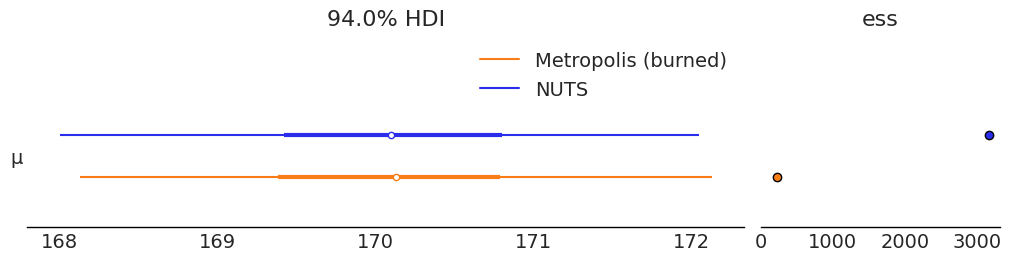

In [ ]:
az.plot_forest([idata_good, idata_burned], model_names=['NUTS', 'Metropolis (burned)'],
               var_names=['μ'], ess=True, combined=True, figsize=(10, 2.5));

<div dir="rtl">

### שגיאת מונטה-קרלו (MCSE)

ממוצע הדגימות הוא רק *אומדן* של הממוצע הפוסטריורי האמיתי. שגיאת התקן של האומדן הזה נקראת **שגיאת מונטה-קרלו**, והיא תלויה ב-ESS — לא במספר הדגימות הגולמי:

$$\text{MCSE} \approx \frac{\text{sd}(\theta \mid y)}{\sqrt{\text{ESS}}}$$

כך ה-ESS מתורגם למשהו מוחשי: *כמה ספרות אחרי הנקודה אפשר לסמוך עליהן?*

</div>

In [ ]:
for name, idata in [('good', idata_good), ('burned', idata_burned)]:
    post = idata.posterior['μ']
    sd = float(post.std())
    ess = float(az.ess(idata, var_names=['μ'])['μ'])
    mcse = float(az.mcse(idata, var_names=['μ'])['μ'])
    print(f'{name:7s}: mean = {float(post.mean()):.3f}   sd/sqrt(ESS) = {sd / np.sqrt(ess):.3f}   az.mcse = {mcse:.3f}')

good   : mean = 170.102   sd/sqrt(ESS) = 0.019   az.mcse = 0.019
burned : mean = 170.085   sd/sqrt(ESS) = 0.070   az.mcse = 0.071


<div dir="rtl">

## 6. האם דילול (thinning) עוזר?

רעיון מפתה: אם דגימות עוקבות תלויות, נשמור רק כל דגימה עשירית — ואז האוטוקורלציה תקטן. זה נכון, אבל **זה לא מגדיל את ה-ESS**. זורקים 90% מהדגימות, וכל אחת מהן נשאה *קצת* מידע. בסוף ה-ESS נשאר כמו שהיה, או קטן.

</div>

In [ ]:
rows = {}
for k in [1, 2, 5, 10, 20]:
    thinned = idata_burned.sel(draw=slice(None, None, k))
    x = thinned.posterior['μ'].values
    rows[f'every {k}'] = {'draws': x.size,
                          'lag-1 autocorr': autocorr(x[0], 1),
                          'ess_bulk': float(az.ess(thinned, var_names=['μ'])['μ'])}
pd.DataFrame(rows).T.round(2)

,draws,lag-1 autocorr,ess_bulk
every 1,2000.0,0.85,231.86
every 2,1000.0,0.71,238.65
every 5,400.0,0.36,236.74
every 10,200.0,0.04,190.23
every 20,100.0,-0.07,81.48


<div dir="rtl">

האוטוקורלציה אכן יורדת, אבל ה-ESS לא עולה. דילול שימושי רק כדי לחסוך בזיכרון או בדיסק — לא כדי לשפר את ההסקה. הפתרון האמיתי לערבוב גרוע הוא **דוגם טוב יותר** (כמו NUTS), **יותר דגימות**, או **פרמטריזציה טובה יותר של המודל**.

</div>

<div dir="rtl">

## 7. הכול בטבלה אחת: `az.summary`

בפועל לא מחשבים כל מדד בנפרד. `az.summary` מחזיר את כל המדדים יחד:

| עמודה | מה היא אומרת | ערך תקין |
|---|---|---|
| `r_hat` | האם השרשראות הסכימו זו עם זו | פחות מ-1.01 |
| `ess_bulk` | מידע על מרכז ההתפלגות | לפחות 100 לשרשרת |
| `ess_tail` | מידע על הזנבות וה-HDI | לפחות 100 לשרשרת |
| `mcse_mean` | דיוק אומדן הממוצע | קטן ביחס ל-`sd` |

</div>

In [ ]:
az.summary(idata_good)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
μ,170.102,1.071,168.005,172.042,0.019,0.013,3264.0,2383.0,1.0
σ,5.675,0.810,4.243,7.121,0.014,0.010,3420.0,2551.0,1.0


In [ ]:
az.summary(idata_bad)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
μ,170.713,13.114,129.529,195.176,3.977,2.895,17.0,14.0,1.17
σ,9.178,10.007,4.135,30.580,2.506,1.805,38.0,25.0,1.11


In [ ]:
az.summary(idata_burned)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
μ,170.085,1.067,168.135,172.126,0.071,0.050,232.0,266.0,1.02
σ,5.708,0.763,4.349,7.039,0.057,0.041,187.0,225.0,1.03


<div dir="rtl">

ההשוואה לממוצע המדגם מראה מה הבעיה בפועל: הדגימה הרעה, בלי חיתוך, מדווחת על סטיית תקן פוסטריורית גדולה בערך פי 12 מהאמיתית (שצריכה להיות בסביבת $s/\sqrt{n} \approx 1$), ועל HDI רחב בעשרות סנטימטרים. ומכיוון שהתחלנו מנקודות סימטריות סביב 170, גם הממוצע יוצא "בערך נכון" — וזה בדיוק המקרה המסוכן: **ממוצע שנראה סביר אינו הוכחה להתכנסות.** רק $\hat{R}$ ו-ESS חושפים שמשהו לא בסדר.

</div>

In [ ]:
compare = pd.DataFrame({
    'NUTS':                 az.summary(idata_good, var_names=['μ']).iloc[0],
    'Metropolis (bad)':     az.summary(idata_bad, var_names=['μ']).iloc[0],
    'Metropolis (burned)':  az.summary(idata_burned, var_names=['μ']).iloc[0],
}).T[['mean', 'sd', 'hdi_3%', 'hdi_97%', 'ess_bulk', 'r_hat']]

print(f'sample mean = {heights.mean():.2f},  s / sqrt(n) = {heights.std(ddof=1) / np.sqrt(len(heights)):.2f}')
compare

sample mean = 170.12,  s / sqrt(n) = 0.99


,mean,sd,hdi_3%,hdi_97%,ess_bulk,r_hat
NUTS,170.102,1.071,168.005,172.042,3264.0,1.00
Metropolis (bad),170.713,13.114,129.529,195.176,17.0,1.17
Metropolis (burned),170.085,1.067,168.135,172.126,232.0,1.02


<div dir="rtl">

## סיכום: רשימת בדיקה אחרי כל דגימה

1. **אזהרות של PyMC** — לא להתעלם מהן (`r_hat`, ESS, divergences)
2. **`az.summary`** — לוודא ש-$\hat{R} < 1.01$ ושה-ESS גדול מ-100 לכל שרשרת, גם ב-bulk וגם ב-tail
3. **`az.plot_trace` / `az.plot_rank`** — לחפש "זחל שעיר" והיסטוגרמות דרגות שטוחות
4. **`az.plot_autocorr`** — אוטוקורלציה שדועכת מהר
5. **כמה שרשראות מנקודות התחלה שונות** — הן צריכות להגיע לאותו מקום
6. **לזכור** — אבחון תקין לא *מוכיח* התכנסות, והתכנסות לא מוכיחה שהמודל טוב (לשם כך: posterior predictive checks)

## תרגילים

1. הריצו שוב את הדגימה הרעה עם `tune=1000` (ועדיין עם `pm.Metropolis()`). מה קורה ל-$\hat{R}$ ול-ESS? למה?
2. החליפו את נקודות ההתחלה כך שכל השרשראות מתחילות ב-$\mu = 110$. האם $\hat{R}$ עדיין מזהה את הבעיה בלי חיתוך? מה המסקנה לגבי חשיבותן של נקודות התחלה *מפוזרות*?
3. הריצו NUTS עם `draws=50` בלבד. בדקו את `ess_tail` — האם אפשר לסמוך על גבולות ה-HDI?
4. חשבו את `rhat_classic` על **שרשרת אחת** שחולקה לשני חצאים (split R-hat). הדגימו שהוא מזהה שרשרת שעדיין "זוחלת", גם כשיש רק שרשרת אחת.

</div>